# 02. Khám phá quy trình (SQ1)

Khóa luận: *Ứng dụng Process Mining và học máy trong kiểm tra tuân thủ và cảnh báo sớm sai lệch quy trình Mua hàng - Thanh toán trên ERP SAP: Nghiên cứu dữ liệu BPI Challenge 2019.* Người thực hiện: Trần Xuân Ái.

Notebook này tái tạo toàn bộ kết quả SQ1 của Chương 4 (Mục 4.1) theo thứ tự đã thống nhất:

1. Tổng quan nhật ký sau tiền xử lý (Bảng 4.1)
2. Đồ thị trực tiếp kế tiếp, DFG (Hình 4.1)
3. Biến thể quy trình (Bảng 4.2)
4. Mô hình chuẩn hai nhánh: dựng Petri net, ghi file `.pnml`, kiểm thử bằng vết giả lập
5. Mô hình khám phá bằng Inductive Miner (IMf), so sánh với mô hình chuẩn (Hình 4.2, Bảng 4.3)
6. Hai nhánh của luồng 3-way match, hóa đơn trước nhận hàng (Bảng 4.4)
7. Nhận hàng và ghi nhận hóa đơn nhiều lần (Bảng 4.5)
8. Đối chiếu với mô hình chuẩn bằng alignment theo biến thể (Bảng 4.6)
9. Tài khoản batch và tài khoản thanh toán tập trung (Mục 4.1.8)

**Cách chạy.** Mở notebook từ thư mục gốc `ma_nguon_kltn` (các module nằm trong `src/`). Đường dẫn log lấy từ `src/cau_hinh.py`: mặc định `du_lieu/BPI_Challenge_2019.xes`, hoặc đặt biến môi trường `KLTN_LOG`. Chọn *Run All*. Cần `pandas`, `numpy`, `pm4py`. Hình màu cần Graphviz (lệnh `dot` có trong PATH); nếu không có, notebook vẫn ghi file `.dot` để vẽ sau. Toàn bộ kết quả ghi vào thư mục `ket_qua_02_kham_pha/`.

In [1]:
from pathlib import Path
import contextlib, os, shutil, subprocess, sys, time

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

sys.dont_write_bytecode = True  # không tạo src/__pycache__
sys.path.insert(0, str(Path("src").resolve()))  # các module nằm trong src/
import cau_hinh

import g4_kiem_tra as g4
import g5_kiem_tra as g5
import sq1_kham_pha as sq1
import sq1_imf as imf
import sq2_tuan_thu as sq2
from r5_v2_phan_loai_clear import GR, IR, CLEAR, buoc2_moc_trich_xuat, loc_pham_vi, phan_loai_clear, sap_xep

LOG = str(cau_hinh.LOG)
CONG_TY = "companyID_0000"
RA = Path("ket_qua_02_kham_pha")
RA.mkdir(exist_ok=True)
pm4py = sq1.nap_pm4py()
assert pm4py is not None, "Chưa có pm4py: chạy  pip install pm4py  rồi mở lại notebook."
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)


def vn(x, dang=","):
    # Định dạng số kiểu Việt Nam: 1.234 và 3,50.
    return format(x, dang).replace(",", "X").replace(".", ",").replace("X", ".")


def pt(n, N, so_le=2):
    return f"{vn(int(n))} ({vn(n / N, f'.{so_le}%')})"


def ve(dot_text, ten, rong=None):
    # Ghi file .dot; nếu có Graphviz thì vẽ PNG và hiển thị.
    (RA / f"{ten}.dot").write_text(dot_text, encoding="utf-8")
    dot = shutil.which("dot")
    if dot is None:
        print(f"Chưa có Graphviz trong PATH: đã ghi {ten}.dot, cài Graphviz rồi chạy lại ô này để có hình.")
        return
    subprocess.run([dot, "-Tpng", "-Gdpi=200", "-o", str(RA / f"{ten}.png"), str(RA / f"{ten}.dot")],
                   check=True, capture_output=True)
    display(Image(filename=str(RA / f"{ten}.png"), width=rong))


@contextlib.contextmanager
def im_canh_bao_font():
    # Graphviz trên Windows in cảnh báo Pango về font ra stderr; hình vẫn đúng nên tạm chặn stderr.
    cu = os.dup(2)
    rong_ = os.open(os.devnull, os.O_WRONLY)
    os.dup2(rong_, 2)
    try:
        yield
    finally:
        os.dup2(cu, 2)
        os.close(rong_)
        os.close(cu)

## 0. Đọc nhật ký và thu hẹp phạm vi

Dùng đúng các bước tiền xử lý của Chương 3: thời điểm trích xuất (Mục 3.1.4), phễu lọc (Mục 3.1.5), phân loại Clear Invoice với Δ = 60 phút (Mục 3.2.1) và trạng thái dòng hàng theo định nghĩa cuối (Mục 3.2.2). Mỗi case là một dòng hàng của đơn mua hàng.

In [2]:
t0 = time.time()
raw = sq2.doc_log(LOG)
moc, _, _ = buoc2_moc_trich_xuat(raw, None)
pv = loc_pham_vi(raw, CONG_TY, moc)
ev = sap_xep(raw[raw["case"].isin(pv)])
idx = pd.Index(sorted(pv), name="case")
N = len(idx)

loai, _, _ = phan_loai_clear(ev, g4.DELTA)
trang_thai = g5.trang_thai_cac_dinh_nghia(g5.so_lieu_case(ev, pv, loai))["moi"].reindex(idx)
xong = trang_thai == "Hoàn tất"

print(f"Đọc và tiền xử lý xong sau {time.time() - t0:,.0f} giây.")
print(f"Thời điểm trích xuất: {moc}")
print(f"Phạm vi: {vn(N)} dòng hàng, {vn(len(ev))} sự kiện, {ev['act'].nunique()} loại hoạt động.")
for tt in ["Hoàn tất", "Còn mở", "Bị xóa"]:
    m = trang_thai == tt
    print(f"  {tt}: {pt(m.sum(), N)} dòng hàng, {vn(int(ev['case'].isin(idx[m]).sum()))} sự kiện")

Đọc và tiền xử lý xong sau 56 giây.
Thời điểm trích xuất: 2019-01-18 13:34:00
Phạm vi: 210.887 dòng hàng, 1.175.650 sự kiện, 28 loại hoạt động.
  Hoàn tất: 163.619 (77,59%) dòng hàng, 963.315 sự kiện
  Còn mở: 39.988 (18,96%) dòng hàng, 194.018 sự kiện
  Bị xóa: 7.280 (3,45%) dòng hàng, 18.317 sự kiện


## 1. Tổng quan nhật ký (Bảng 4.1)

Sự kiện chỉ ghi đến ngày (Vendor creates invoice, Vendor creates debit memo, mang giờ 23:59 địa phương) được dời về 00:00 giờ địa phương cùng ngày trước khi tính tần suất, DFG và biến thể, để không tạo cạnh giả (Mục 3.7.2). Các mục còn lại dùng timestamp gốc.

In [3]:
ev_ngay = sq1.doi_ve_dau_ngay(ev)
hd = sq1.tan_suat_hoat_dong(ev_ngay)
hd["ty_le_dong_hang"] = hd["so_case"] / N
hd.to_csv(RA / "tan_suat_hoat_dong.csv", encoding="utf-8-sig")
bang41 = hd[hd["ty_le_dong_hang"] >= 0.012].copy()
bang41["ty_le_dong_hang"] = (bang41["ty_le_dong_hang"] * 100).round(1)
display(bang41[["so_su_kien", "so_case", "ty_le_dong_hang", "so_case_bat_dau", "so_case_ket_thuc"]])
print(f"{len(hd) - len(bang41)} hoạt động còn lại xuất hiện ở dưới 1,2% dòng hàng.")
ket_thuc_clear = (ev_ngay.groupby("case")["act"].last() == CLEAR).sum()
print(f"Dòng hàng kết thúc bằng Clear Invoice: {pt(ket_thuc_clear, N, 1)}")

,so_su_kien,so_case,ty_le_dong_hang,so_case_bat_dau,so_case_ket_thuc
act,,,,,
Record Goods Receipt,212458,197416,93.6,9,6283
Create Purchase Order Item,210887,210887,100.0,158301,3409
Record Invoice Receipt,200593,191551,90.8,0,20232
Vendor creates invoice,195707,191018,90.6,10946,1
Clear Invoice,173256,166980,79.2,0,165279
Remove Payment Block,53217,52197,24.8,0,5085
Create Purchase Requisition Item,41393,41393,19.6,41309,0
Receive Order Confirmation,31273,31269,14.8,0,215
Change Quantity,16607,13602,6.4,0,368


15 hoạt động còn lại xuất hiện ở dưới 1,2% dòng hàng.
Dòng hàng kết thúc bằng Clear Invoice: 165.279 (78,4%)


## 2. Đồ thị trực tiếp kế tiếp (Hình 4.1)

Giữ ít cạnh nhất (theo tần suất giảm dần) đủ phủ 95% số lần chuyển. Nhãn cạnh: số lần chuyển | thời gian trung vị giữa hai hoạt động. Cạnh càng dày và càng đậm thì càng nhiều lần chuyển; màu nút theo giai đoạn của quy trình.

358 cạnh, 964.763 lần chuyển. Giữ 34 cạnh phủ 95,1% số lần chuyển và 13 hoạt động.


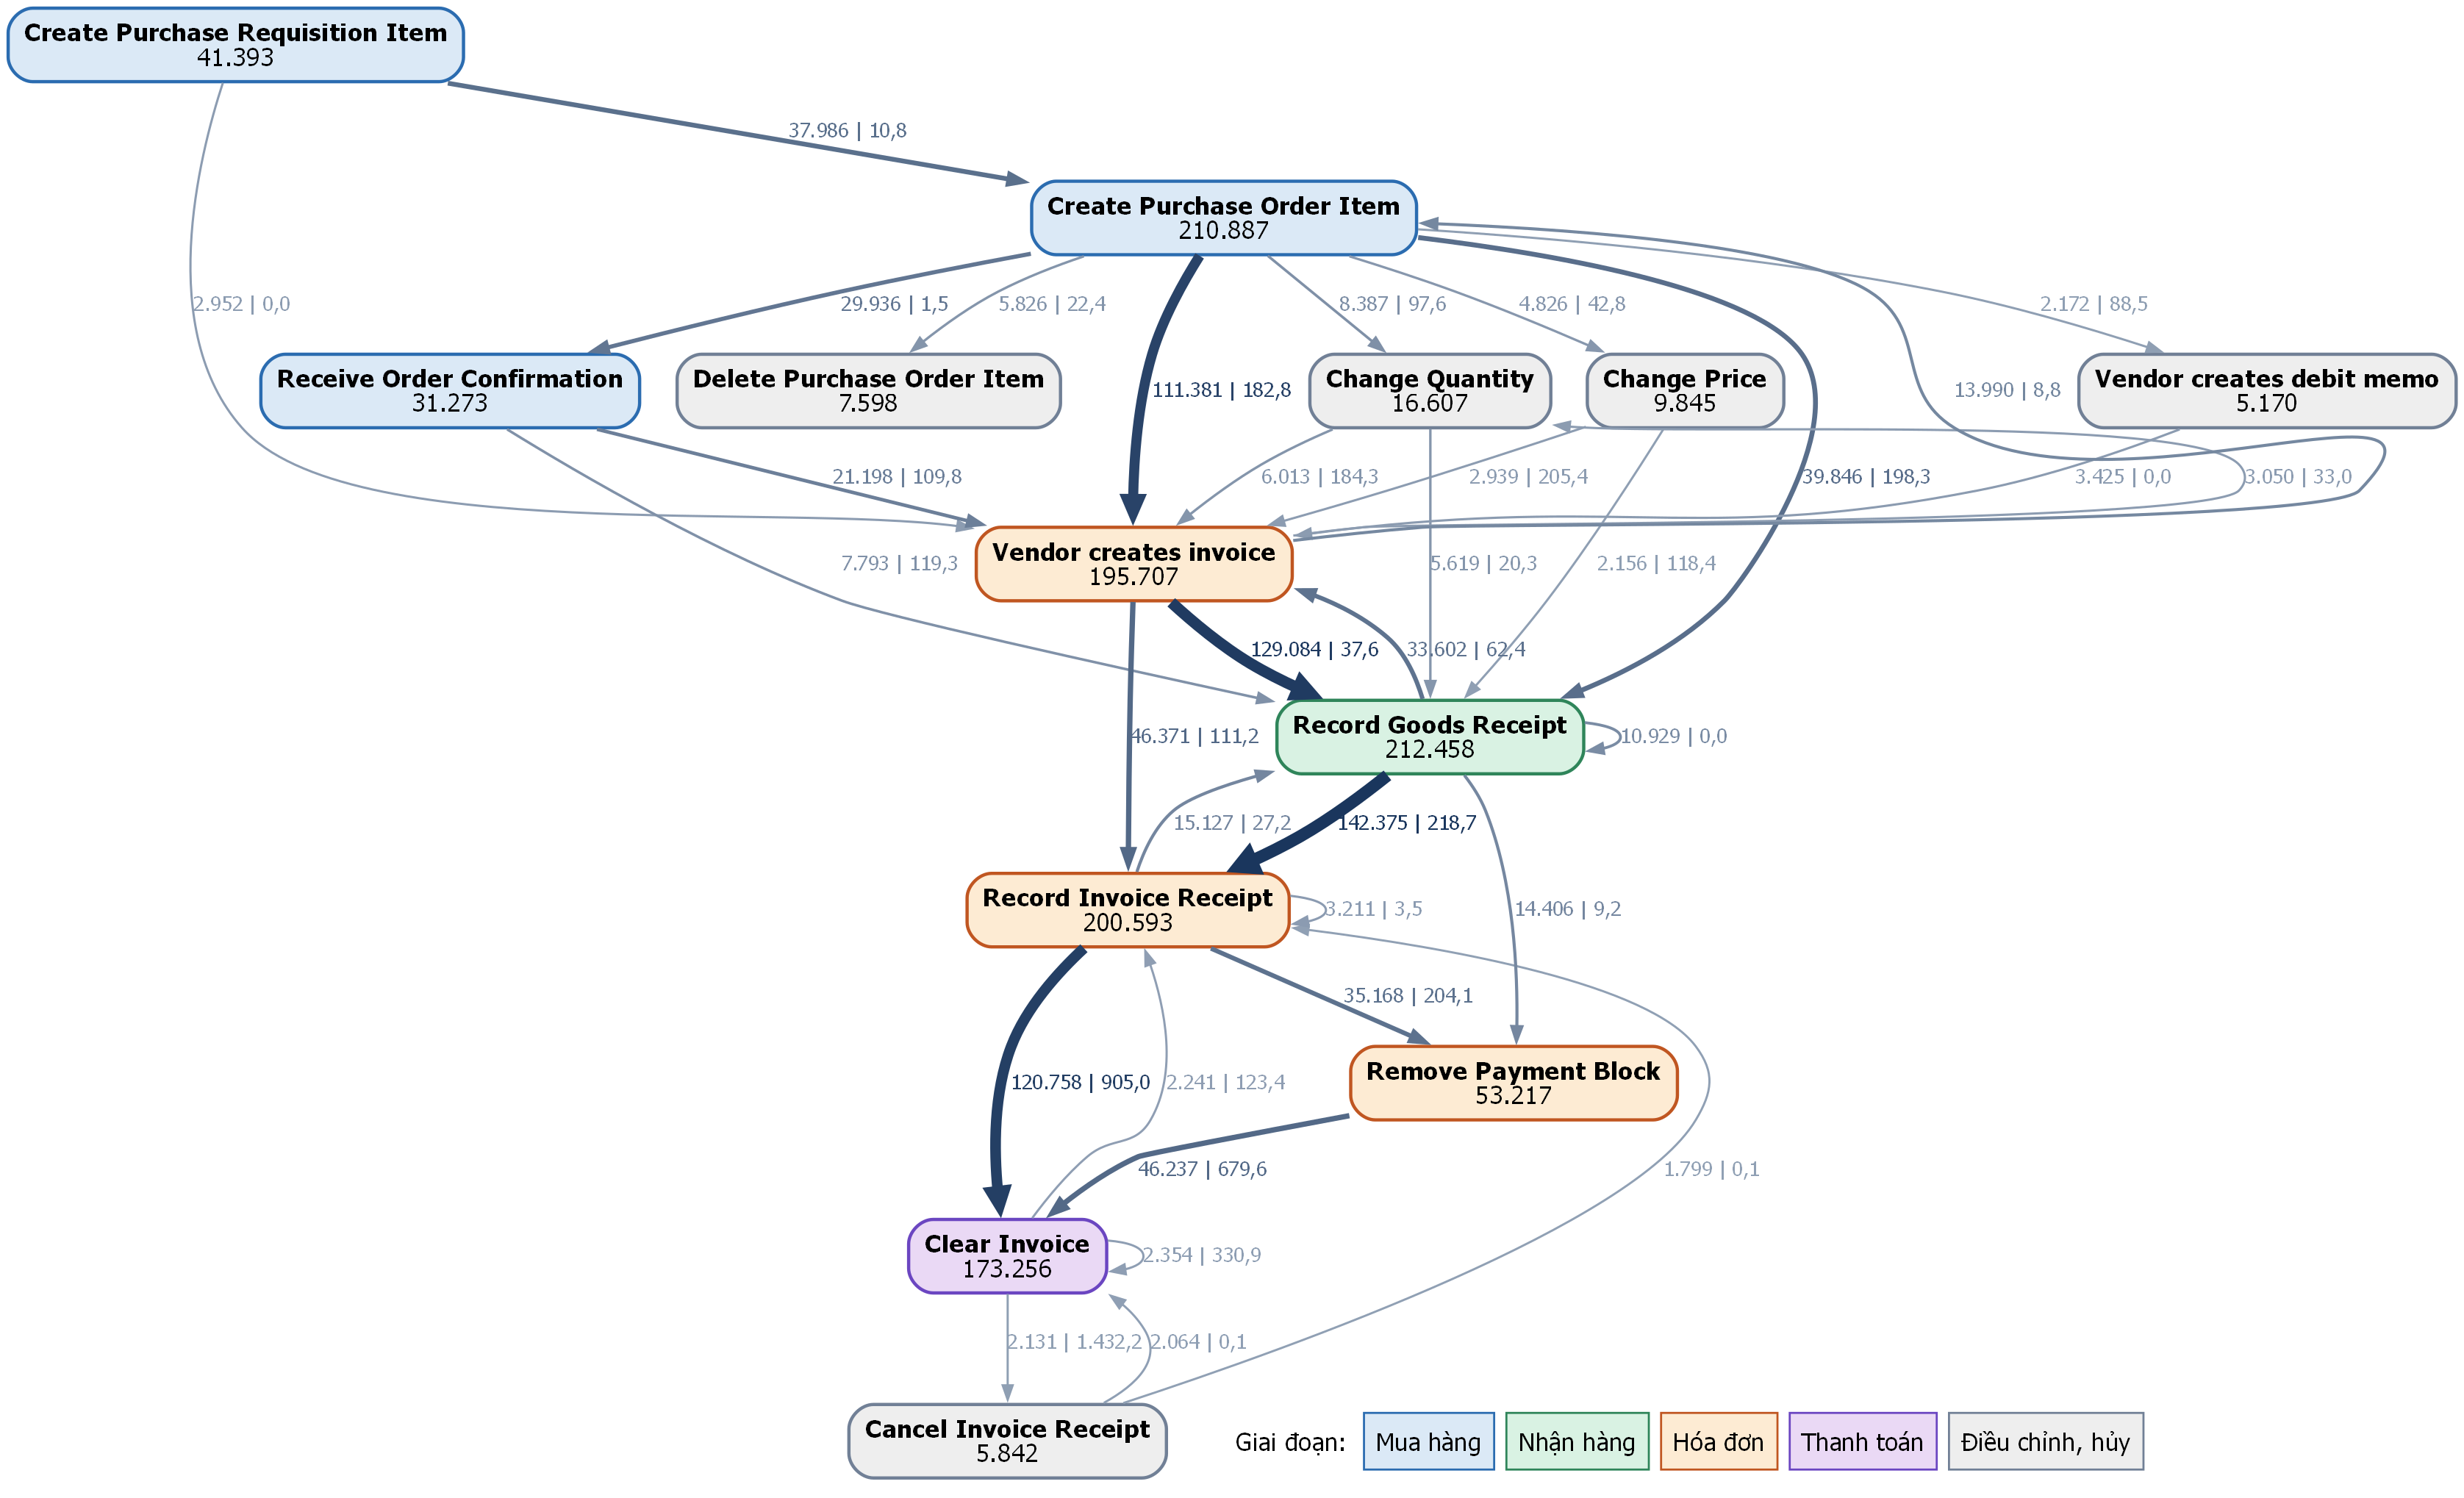

,tu,den,so_lan,so_case,trung_vi_gio
0,Record Goods Receipt,Record Invoice Receipt,142375,141858,218.7
1,Vendor creates invoice,Record Goods Receipt,129084,127667,37.6
2,Record Invoice Receipt,Clear Invoice,120758,120045,905.0
3,Create Purchase Order Item,Vendor creates invoice,111381,111381,182.8
4,Vendor creates invoice,Record Invoice Receipt,46371,46208,111.2
5,Remove Payment Block,Clear Invoice,46237,45983,679.6
6,Create Purchase Order Item,Record Goods Receipt,39846,39846,198.3
7,Create Purchase Requisition Item,Create Purchase Order Item,37986,37986,10.8
8,Record Invoice Receipt,Remove Payment Block,35168,34849,204.0
9,Record Goods Receipt,Vendor creates invoice,33602,33376,62.4


In [4]:
bang_dfg = sq1.dfg(ev_ngay)
bang_dfg.round({"trung_vi_gio": 2, "trung_binh_gio": 2}).to_csv(RA / "dfg_canh.csv", index=False, encoding="utf-8-sig")
canh = sq1.loc_canh(bang_dfg)
nut = sorted(set(canh["tu"]) | set(canh["den"]))
print(f"{vn(len(bang_dfg))} cạnh, {vn(int(bang_dfg['so_lan'].sum()))} lần chuyển. Giữ {len(canh)} cạnh phủ "
      f"{vn(canh['ty_le'].sum(), '.1%')} số lần chuyển và {len(nut)} hoạt động.")

NHOM = {"mua": ("#dbe9f6", "#2b6cb0"), "nhan": ("#d9f2e3", "#2f855a"), "hd": ("#fdebd3", "#c05621"),
        "tt": ("#ead9f5", "#6b46c1"), "dc": ("#eeeeee", "#718096")}
GIAI_DOAN = {"Create Purchase Requisition Item": "mua", "Create Purchase Order Item": "mua", "Receive Order Confirmation": "mua",
             "Record Goods Receipt": "nhan", "Record Invoice Receipt": "hd", "Vendor creates invoice": "hd",
             "Remove Payment Block": "hd", "Clear Invoice": "tt"}
THU_TU = {"Create Purchase Requisition Item": 0, "Create Purchase Order Item": 1, "Receive Order Confirmation": 2,
          "Change Price": 2, "Change Quantity": 2, "Delete Purchase Order Item": 2, "Vendor creates invoice": 3,
          "Vendor creates debit memo": 3, "Record Goods Receipt": 4, "Record Invoice Receipt": 5,
          "Remove Payment Block": 6, "Clear Invoice": 7, "Cancel Invoice Receipt": 8}


def dot_dfg(canh, hd):
    lon = canh["so_lan"].max()
    d = ["digraph DFG {", "  rankdir=TB; nodesep=0.25; ranksep=0.5; bgcolor=white;",
         '  node [shape=box, style="rounded,filled", fontname="Times New Roman", fontsize=12, penwidth=1.6];',
         '  edge [fontname="Times New Roman", fontsize=10, arrowsize=0.7];']
    for n in nut:
        nen, vien = NHOM[GIAI_DOAN.get(n, "dc")]
        d.append(f'  "{n}" [label=<<b>{n}</b><br/>{vn(int(hd.loc[n, "so_su_kien"]))}>, fillcolor="{nen}", color="{vien}"];')
    for r in canh.itertuples():
        x = (r.so_lan / lon) ** 0.5
        mau = "#%02x%02x%02x" % tuple(int(a + (b - a) * x) for a, b in zip((160, 174, 192), (26, 54, 93)))
        nguoc = "" if THU_TU.get(r.tu, 5) < THU_TU.get(r.den, 5) else ", constraint=false"
        d.append(f'  "{r.tu}" -> "{r.den}" [label="{vn(int(r.so_lan))} | {vn(r.trung_vi_gio, ",.1f")}", '
                 f'penwidth={1 + 5 * r.so_lan / lon:.2f}, color="{mau}", fontcolor="{mau}"{nguoc}];')
    o = "".join(f'<td bgcolor="{NHOM[k][0]}" border="1" color="{NHOM[k][1]}" cellpadding="5">{ten}</td>'
                for k, ten in [("mua", "Mua hàng"), ("nhan", "Nhận hàng"), ("hd", "Hóa đơn"), ("tt", "Thanh toán"),
                               ("dc", "Điều chỉnh, hủy")])
    d.append(f'  chu_giai [shape=plaintext, style="", label=<<table border="0" cellspacing="6"><tr><td>Giai đoạn:</td>{o}</tr></table>>];')
    if "Create Purchase Requisition Item" in nut:
        d.append('  { rank=min; "Create Purchase Requisition Item"; }')
    d += ["  { rank=max; chu_giai; }", "}"]
    return "\n".join(d)


ve(dot_dfg(canh, hd), "hinh_4_1_dfg", rong=800)
display(canh.head(10)[["tu", "den", "so_lan", "so_case", "trung_vi_gio"]].round(1))

## 3. Biến thể quy trình (Bảng 4.2)

Biến thể được tính trên hai góc nhìn: toàn bộ hoạt động, và chỉ 7 hoạt động của mô hình chuẩn (PR, PO, OC, GR, IR, RPB, Clear).

In [5]:
TAT = {"Create Purchase Requisition Item": "PR", "Create Purchase Order Item": "PO", "Receive Order Confirmation": "OC",
       "Record Goods Receipt": "GR", "Record Invoice Receipt": "IR", "Remove Payment Block": "RPB", "Clear Invoice": "Clear",
       "Vendor creates invoice": "VINV"}


def viet_tat(s):
    return " → ".join(TAT.get(a, a) for a in s.split(sq1.MUI_TEN))


for nhan, chi_giu, ten in [("toàn bộ hoạt động", None, "bien_the.csv"), ("góc nhìn mô hình (7 hoạt động)", sq1.HD_MO_HINH, "bien_the_mo_hinh.csv")]:
    bt, n95 = sq1.bien_the(ev_ngay, pv, chi_giu)
    bt.to_csv(RA / ten, index=False, encoding="utf-8-sig")
    print(f"{nhan}: {vn(len(bt))} biến thể; {vn(n95)} biến thể phủ 95% số dòng hàng; "
          f"10 biến thể đầu phủ {vn(bt['ty_le_tich_luy'].iloc[min(9, len(bt) - 1)], '.1%')}.")
    if chi_giu is not None:
        b = bt.head(10).assign(bien_the=lambda x: x["bien_the"].map(viet_tat),
                               ty_le=lambda x: (x["ty_le"] * 100).round(2), ty_le_tich_luy=lambda x: (x["ty_le_tich_luy"] * 100).round(2))
        display(b[["hang", "bien_the", "so_case", "ty_le", "ty_le_tich_luy"]])

toàn bộ hoạt động: 7.122 biến thể; 547 biến thể phủ 95% số dòng hàng; 10 biến thể đầu phủ 61,8%.
góc nhìn mô hình (7 hoạt động): 1.519 biến thể; 34 biến thể phủ 95% số dòng hàng; 10 biến thể đầu phủ 82,3%.


,hang,bien_the,so_case,ty_le,ty_le_tich_luy
0,1,PO → GR → IR → Clear,85089,40.35,40.35
1,2,PO → GR → IR → RPB → Clear,22510,10.67,51.02
2,3,PO → OC → GR → IR → Clear,14923,7.08,58.10
3,4,PR → PO → GR → IR → Clear,11843,5.62,63.71
4,5,PO → IR → GR → RPB → Clear,10103,4.79,68.50
5,6,PO,8870,4.21,72.71
6,7,PR → PO → GR → IR,7356,3.49,76.20
7,8,PO → GR → IR,6468,3.07,79.27
8,9,PR → PO → OC → GR → IR,3490,1.65,80.92
9,10,PO → GR,2893,1.37,82.29


## 4. Mô hình chuẩn hai nhánh và file `.pnml`

Mô hình chuẩn được xây độc lập với dữ liệu (Mục 3.3): PR (tùy chọn) → PO → OC (tùy chọn) → chọn một trong hai nhánh:

- (a) GR → IR → RPB (tùy chọn) → Clear
- (b) IR → GR → RPB (bắt buộc) → Clear

Petri net được ghi ra `QuyTrinhChuan_P2P_2nhanh.pnml`, đọc lại từ chính file đó và kiểm thử bằng alignment trên 8 vết giả lập: 4 vết hợp lệ phải có fitness = 1, 4 vết sai phải có fitness < 1.

Đã ghi ket_qua_02_kham_pha\QuyTrinhChuan_P2P_2nhanh.pnml: 11 place, 14 transition (3 chuyển tiếp ẩn).


,vet,chuoi,ky_vong,fitness,ket_qua
0,a_hop_le,PO → GR → IR → Clear,fitness = 1,1.0000,ĐẠT
1,a_hop_le_co_rpb,PO → GR → IR → RPB → Clear,fitness = 1,1.0000,ĐẠT
2,b_hop_le,PO → IR → GR → RPB → Clear,fitness = 1,1.0000,ĐẠT
3,day_du_pr_oc,PR → PO → OC → GR → IR → Clear,fitness = 1,1.0000,ĐẠT
4,b_thieu_rpb,PO → IR → GR → Clear,fitness < 1,0.8750,ĐẠT
5,tra_truoc_nhan_hang,PO → IR → Clear → GR,fitness < 1,0.7500,ĐẠT
6,clear_truoc_ir,PO → GR → Clear → IR,fitness < 1,0.7500,ĐẠT
7,thieu_po,GR → IR → Clear,fitness < 1,0.8571,ĐẠT


Mô hình chuẩn đạt cả 8 vết giả lập.


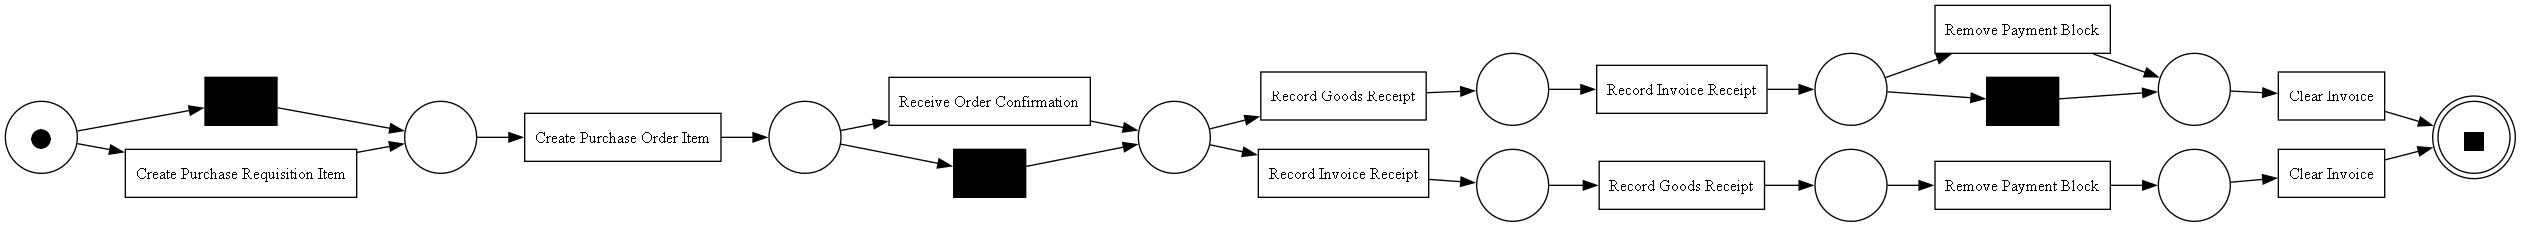

In [6]:
net, im, fm = sq1.mo_hinh_chuan(pm4py)
TEP_PNML = RA / sq1.TEN_PNML
pm4py.write_pnml(net, im, fm, str(TEP_PNML))
chuan = pm4py.read_pnml(str(TEP_PNML))
print(f"Đã ghi {TEP_PNML}: {len(chuan[0].places)} place, {len(chuan[0].transitions)} transition "
      f"({sum(t.label is None for t in chuan[0].transitions)} chuyển tiếp ẩn).")
kiem_thu = sq1.kiem_thu_mo_hinh(*chuan)
kiem_thu.to_csv(RA / "kiem_thu_mo_hinh.csv", index=False, encoding="utf-8-sig")
display(kiem_thu.assign(chuoi=kiem_thu["chuoi"].map(viet_tat))[["vet", "chuoi", "ky_vong", "fitness", "ket_qua"]])
assert (kiem_thu["ket_qua"] == "ĐẠT").all(), "Mô hình chuẩn không đạt vết giả lập, dừng lại kiểm tra."
print("Mô hình chuẩn đạt cả 8 vết giả lập.")
if shutil.which("dot"):
    with im_canh_bao_font():
        pm4py.save_vis_petri_net(*chuan, str(RA / "mo_hinh_chuan_petri.png"))
    display(Image(filename=str(RA / "mo_hinh_chuan_petri.png"), width=900))

## 5. Mô hình khám phá bằng Inductive Miner (Hình 4.2, Bảng 4.3)

IMf với ngưỡng nhiễu 0,2, trên góc nhìn 7 hoạt động, khám phá hai lần: từ toàn bộ phạm vi và từ riêng dòng hàng hoàn tất. Fitness và precision (Align-ETConformance) của IMf và của mô hình chuẩn được tính trên toàn bộ biến thể của mỗi tập. Bước này chạy lâu nhất của notebook.

In [7]:
vt = sq2.bien_the_mo_hinh(ev, idx)
tap = {"toàn bộ phạm vi": vt, "dòng hàng hoàn tất": vt[xong]}
mo_hinh = {"Mô hình chuẩn hai nhánh": (chuan, None)}
cay_imf = {}
for ten_tap, ten_tep in [("toàn bộ phạm vi", "imf_toan_bo"), ("dòng hàng hoàn tất", "imf_hoan_tat")]:
    cay, n_, i_, f_ = imf.kham_pha_imf(pm4py, tap[ten_tap].value_counts(), imf.NGUONG_NHIEU)
    pm4py.write_pnml(n_, i_, f_, str(RA / f"{ten_tep}.pnml"))
    (RA / f"{ten_tep}_cay.txt").write_text(str(cay), encoding="utf-8")
    cay_imf[ten_tap] = cay
    mo_hinh[f"IMf khám phá từ {ten_tap}"] = ((n_, i_, f_), ten_tap)
    print(f"Cây IMf từ {ten_tap}: {cay}")
print("Hai cây giống nhau:", str(cay_imf["toàn bộ phạm vi"]) == str(cay_imf["dòng hàng hoàn tất"]))

rows = []
for ten_mh, ((n_, i_, f_), chi_tap) in mo_hinh.items():
    for ten_tap, v in tap.items():
        if chi_tap == "dòng hàng hoàn tất" and ten_tap != chi_tap:
            continue
        kq, _ = imf.danh_gia(sq2.chon_bien_the(v), n_, i_, f_)
        rows.append({"mo_hinh": ten_mh, "tap_danh_gia": ten_tap, "so_bien_the": kq["so_bien_the"],
                     "fitness": round(kq["fitness"], 4), "khop_hoan_toan_%": round(kq["ty_le_khop_hoan_toan"] * 100, 2),
                     "precision": round(kq["precision"], 4)})
bang43 = pd.DataFrame(rows)
bang43.to_csv(RA / "so_sanh_imf_mo_hinh_chuan.csv", index=False, encoding="utf-8-sig")
display(bang43)

Cây IMf từ toàn bộ phạm vi: ->( X( tau, 'Create Purchase Requisition Item' ), +( *( 'Record Goods Receipt', tau ), ->( 'Create Purchase Order Item', +( *( 'Record Invoice Receipt', tau ), X( tau, *( 'Remove Payment Block', tau ) ), ->( X( tau, *( 'Receive Order Confirmation', tau ) ), *( 'Clear Invoice', tau ) ) ) ) ) )
Cây IMf từ dòng hàng hoàn tất: ->( X( tau, 'Create Purchase Requisition Item' ), +( *( 'Record Goods Receipt', tau ), ->( 'Create Purchase Order Item', +( *( 'Record Invoice Receipt', tau ), X( tau, *( 'Remove Payment Block', tau ) ), ->( X( tau, *( 'Receive Order Confirmation', tau ) ), *( 'Clear Invoice', tau ) ) ) ) ) )
Hai cây giống nhau: True


,mo_hinh,tap_danh_gia,so_bien_the,fitness,khop_hoan_toan_%,precision
0,Mô hình chuẩn hai nhánh,toàn bộ phạm vi,34,0.9375,77.39,0.9950
1,Mô hình chuẩn hai nhánh,dòng hàng hoàn tất,11,0.9993,99.33,0.9844
2,IMf khám phá từ toàn bộ phạm vi,toàn bộ phạm vi,34,0.9398,78.83,0.5323
3,IMf khám phá từ toàn bộ phạm vi,dòng hàng hoàn tất,11,1.0000,100.00,0.4513
4,IMf khám phá từ dòng hàng hoàn tất,dòng hàng hoàn tất,11,1.0000,100.00,0.4513


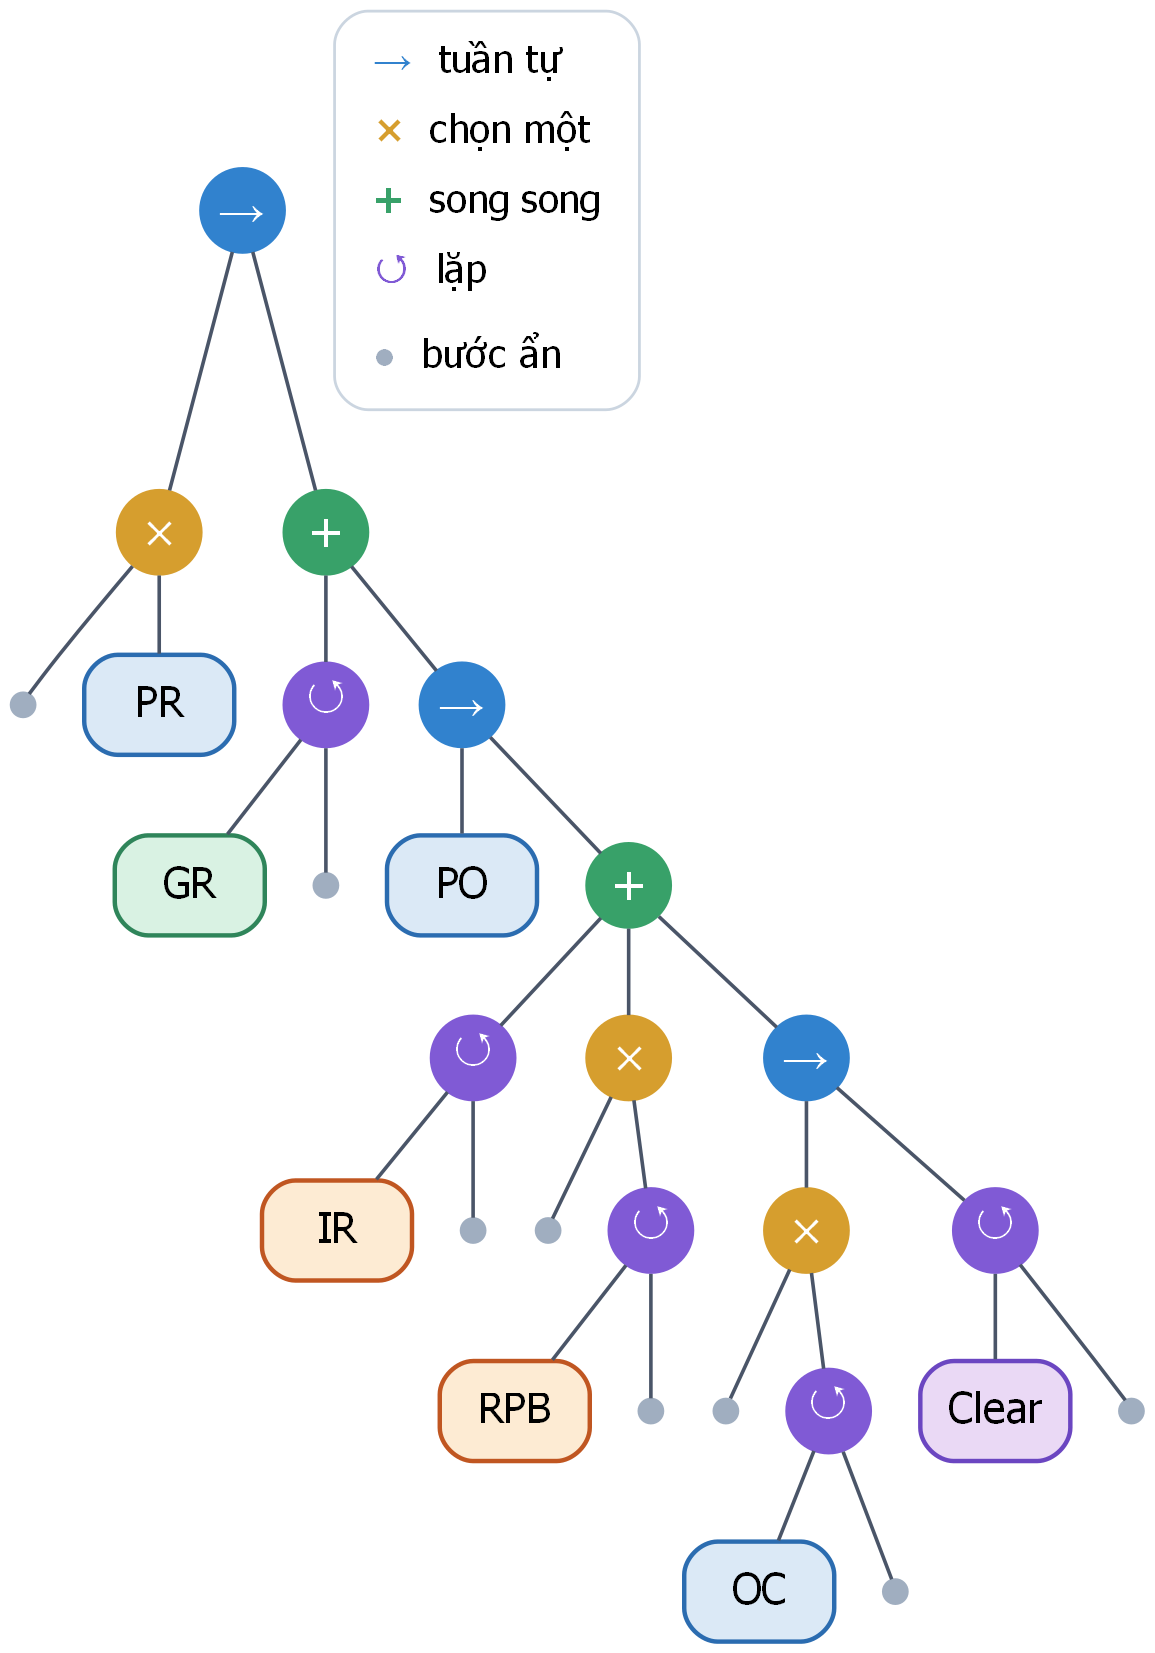

In [8]:
from pm4py.objects.process_tree.obj import Operator

TOAN = {Operator.SEQUENCE: ("→", "#3182ce"), Operator.XOR: ("×", "#d69e2e"), Operator.PARALLEL: ("+", "#38a169"),
        Operator.LOOP: ("↺", "#805ad5")}


def dot_cay(goc):
    d = ["graph T {", "  rankdir=TB; nodesep=0.25; ranksep=0.4; bgcolor=white;",
         '  node [fontname="Times New Roman"]; edge [color="#4a5568", penwidth=1.3];']
    dem = [0]

    def di(n):
        dem[0] += 1
        i = f"n{dem[0]}"
        if n.operator is None:
            if n.label is None:
                d.append(f'  {i} [shape=point, width=0.12, color="#a0aec0"];')
            else:
                nen, vien = NHOM[GIAI_DOAN.get(n.label, "dc")]
                d.append(f'  {i} [label="{TAT.get(n.label, n.label)}", shape=box, style="rounded,filled", fillcolor="{nen}", '
                         f'color="{vien}", penwidth=1.6, fontsize=15];')
            return i
        ky, mau = TOAN[n.operator]
        d.append(f'  {i} [label="{ky}", shape=circle, style=filled, fillcolor="{mau}", fontcolor=white, color="{mau}", '
                 f'fontsize=17, width=0.42, fixedsize=true];')
        for c in n.children:
            d.append(f"  {i} -- {di(c)};")
        return i

    di(goc)
    o = "".join(f'<tr><td align="left"><font color="{m}"><b>{k}</b></font>  {t}</td></tr>'
                for (k, m), t in zip(TOAN.values(), ["tuần tự", "chọn một", "song song", "lặp"]))
    o += '<tr><td align="left"><font color="#a0aec0">●</font>  bước ẩn</td></tr>'
    d.append(f'  chu_giai [shape=box, style=rounded, color="#cbd5e0", fontsize=14, label=<<table border="0" cellspacing="4">{o}</table>>];')
    d += ["  { rank=min; n1; chu_giai; }", "}"]
    return "\n".join(d)


ve(dot_cay(cay_imf["toàn bộ phạm vi"]), "hinh_4_2_cay_imf", rong=420)

## 6. Hai nhánh của luồng 3-way match, hóa đơn trước nhận hàng (Bảng 4.4)

Thứ tự được xác định bằng Record Goods Receipt đầu tiên và Record Invoice Receipt đầu tiên của mỗi dòng hàng; trường hợp cùng timestamp báo cáo riêng.

In [9]:
bang_nhanh, _ = sq1.nhanh(ev, pv)
bang_nhanh.to_csv(RA / "ty_le_nhanh.csv", encoding="utf-8-sig")
b44 = bang_nhanh.assign(ty_le=lambda x: (x["ty_le"] * 100).round(2),
                        ty_le_co_rpb_trong_nhom=lambda x: (x["ty_le_co_rpb_trong_nhom"] * 100).round(2))
display(b44[["so_case", "ty_le", "ty_le_co_rpb_trong_nhom"]])
b = bang_nhanh.loc[sq1.NHOM_NHANH[1]]
print(f"Nhánh (b) không có Remove Payment Block: {pt(b['so_case'] - b['so_case_co_rpb'], b['so_case'])}")

,so_case,ty_le,ty_le_co_rpb_trong_nhom
nhanh,,,
(a) GR trước IR,175935,83.43,21.13
(b) IR trước GR,15293,7.25,96.92
trùng thời điểm,9,0.00,11.11
chỉ có GR,6179,2.93,0.00
chỉ có IR,314,0.15,53.50
không có cả hai,13157,6.24,0.30


Nhánh (b) không có Remove Payment Block: 471 (3,08%)


## 7. Nhận hàng và ghi nhận hóa đơn nhiều lần (Bảng 4.5)

Mô hình chuẩn chỉ cho mỗi bước nhận hàng và ghi nhận hóa đơn xảy ra một lần. Đếm theo số sự kiện Record Goods Receipt và Record Invoice Receipt trên mỗi dòng hàng, không trừ các lần hủy.

In [10]:
n_gr = ev[ev["act"] == GR].groupby("case").size().reindex(idx).fillna(0)
n_ir = ev[ev["act"] == IR].groupby("case").size().reindex(idx).fillna(0)
mot_mot = (n_gr == 1) & (n_ir == 1)
bang45 = pd.DataFrame([
    {"nhom": "Từ 2 lần nhận hàng", "so_dong_hang": int((n_gr >= 2).sum()), "ty_le_pham_vi_%": (n_gr >= 2).mean() * 100,
     "ty_le_tren_dong_co_buoc_%": (n_gr >= 2).sum() / (n_gr >= 1).sum() * 100},
    {"nhom": "Từ 2 lần ghi nhận hóa đơn", "so_dong_hang": int((n_ir >= 2).sum()), "ty_le_pham_vi_%": (n_ir >= 2).mean() * 100,
     "ty_le_tren_dong_co_buoc_%": (n_ir >= 2).sum() / (n_ir >= 1).sum() * 100},
    {"nhom": "Có ít nhất một trong hai", "so_dong_hang": int(((n_gr >= 2) | (n_ir >= 2)).sum()),
     "ty_le_pham_vi_%": ((n_gr >= 2) | (n_ir >= 2)).mean() * 100, "ty_le_tren_dong_co_buoc_%": np.nan},
    {"nhom": "Đúng 1 lần nhận hàng và 1 lần ghi nhận hóa đơn", "so_dong_hang": int(mot_mot.sum()),
     "ty_le_pham_vi_%": mot_mot.mean() * 100, "ty_le_tren_dong_co_buoc_%": np.nan}]).round(2)
bang45.to_csv(RA / "nhieu_lan_nhan_hang_hoa_don.csv", index=False, encoding="utf-8-sig")
display(bang45)

,nhom,so_dong_hang,ty_le_pham_vi_%,ty_le_tren_dong_co_buoc_%
0,Từ 2 lần nhận hàng,6936,3.29,3.51
1,Từ 2 lần ghi nhận hóa đơn,7827,3.71,4.09
2,Có ít nhất một trong hai,11216,5.32,NaN
3,Đúng 1 lần nhận hàng và 1 lần ghi nhận hóa đơn,180222,85.46,NaN


## 8. Đối chiếu với mô hình chuẩn bằng alignment (Bảng 4.6)

Alignment được tính theo biến thể (mỗi biến thể một lần, nhân với số dòng hàng), trên toàn bộ biến thể của từng tập. Bốn tập: toàn bộ phạm vi; chỉ một lần nhận hàng và một lần ghi nhận hóa đơn; dòng hàng hoàn tất; giao của hai tập sau. Fitness là trung bình theo dòng hàng.

In [11]:
cac_tap = [("Toàn bộ phạm vi", pd.Series(True, index=idx)),
           ("Một lần nhận hàng, một lần ghi nhận hóa đơn", mot_mot),
           ("Dòng hàng hoàn tất", xong),
           ("Hoàn tất, một lần nhận hàng và ghi nhận hóa đơn", xong & mot_mot)]
dem_tap = [sq2.chon_bien_the(vt[m]) for _, m in cac_tap]
ds_bt = list(dict.fromkeys(v for dm in dem_tap for v in dm.index))
al = sq2.can_bien_the(ds_bt, *chuan)
rows, lech_tap = [], {}
for (ten, m), dm in zip(cac_tap, dem_tap):
    fit, khop, lech = sq2.tong_hop_alignment(dm, al)
    prec = sq2.precision_theo_tan_suat(dm, *chuan)
    lech_tap[ten] = lech
    rows.append({"tap_dong_hang": ten, "so_dong_hang": int(m.sum()), "so_bien_the": len(dm),
                 "phan_duoc_tinh_%": round(dm.sum() / m.sum() * 100, 2), "fitness": round(fit, 4),
                 "khop_hoan_toan_%": round(khop * 100, 2), "precision": round(prec, 4)})
bang46 = pd.DataFrame(rows)
bang46.to_csv(RA / "alignment_tong_hop.csv", index=False, encoding="utf-8-sig")
display(bang46)
for ten in ["Toàn bộ phạm vi", "Dòng hàng hoàn tất"]:
    print(f"Bước lệch phổ biến, {ten.lower()} (% số dòng hàng được tính):")
    display(lech_tap[ten].head(5).assign(ty_le_dong_hang=lambda x: (x["ty_le_dong_hang"] * 100).round(2)))

,tap_dong_hang,so_dong_hang,so_bien_the,phan_duoc_tinh_%,fitness,khop_hoan_toan_%,precision
0,Toàn bộ phạm vi,210887,34,95.06,0.9375,77.39,0.9950
1,"Một lần nhận hàng, một lần ghi nhận hóa đơn",180222,13,95.58,0.9858,88.98,0.9816
2,Dòng hàng hoàn tất,163619,11,95.05,0.9993,99.33,0.9844
3,"Hoàn tất, một lần nhận hàng và ghi nhận hóa đơn",156177,7,95.83,1.0000,100.00,0.9636


Bước lệch phổ biến, toàn bộ phạm vi (% số dòng hàng được tính):


,loai_buoc_lech,hoat_dong,so_dong_hang,so_lan,ty_le_dong_hang
0,thiếu so với mô hình,Clear Invoice,42095,42095,21.00
2,thiếu so với mô hình,Record Invoice Receipt,18914,18914,9.44
1,thiếu so với mô hình,Record Goods Receipt,13118,13118,6.54
4,thừa trong log,Record Goods Receipt,1705,1705,0.85
5,thừa trong log,Record Invoice Receipt,1539,1539,0.77


Bước lệch phổ biến, dòng hàng hoàn tất (% số dòng hàng được tính):


,loai_buoc_lech,hoat_dong,so_dong_hang,so_lan,ty_le_dong_hang
0,thừa trong log,Record Goods Receipt,1045,1045,0.67


## 9. Tài khoản batch và tài khoản thanh toán tập trung

Tài khoản batch nhận diện theo tên (Mục 3.4.3). user_002 được đối chiếu riêng vì thực hiện gần như toàn bộ Clear Invoice. Giờ trong ngày và thứ trong tuần tính theo giờ Europe/Amsterdam.

In [12]:
ts_dp = g4.gio_dia_phuong(ev, lambda *a: None)
tk = sq1.tai_khoan_batch(ev, ts_dp)
tk.to_csv(RA / "tai_khoan_batch.csv", index=False, encoding="utf-8-sig")
batch = tk[tk["loai"] == "batch"]
print(f"{len(batch)} tài khoản batch, {pt(batch['so_su_kien'].sum(), len(ev), 1)} sự kiện, "
      f"{vn(int(batch['so_clear'].sum()))} lần Clear Invoice.")
u2 = ev["user"].astype(str) == sq1.USER_002
clear = ev["act"] == CLEAR
tra = pd.Series(ev.index.isin(loai.index[loai == "thanh_toan"]), index=ev.index)  # Clear Invoice "thanh toán"
print(f"user_002: {pt(u2.sum(), len(ev), 1)} sự kiện; {pt((u2 & clear).sum(), clear.sum(), 1)} số Clear Invoice; "
      f"{pt((u2 & tra).sum(), tra.sum(), 1)} số Clear Invoice thanh toán.")
thu = ts_dp[u2 & tra].dt.dayofweek.value_counts(normalize=True).sort_index()
TEN_THU = ["thứ Hai", "thứ Ba", "thứ Tư", "thứ Năm", "thứ Sáu", "thứ Bảy", "Chủ nhật"]
print("Lần thanh toán của user_002 theo thứ trong tuần:", "; ".join(f"{TEN_THU[int(k)]} {vn(v, '.1%')}" for k, v in thu.items()))
display(tk.drop(columns=["ty_le_trong_clear"]).head(20))

17 tài khoản batch, 78.841 (6,7%) sự kiện, 0 lần Clear Invoice.
user_002: 149.418 (12,7%) sự kiện; 149.418 (86,2%) số Clear Invoice; 149.418 (87,3%) số Clear Invoice thanh toán.
Lần thanh toán của user_002 theo thứ trong tuần: thứ Hai 0,1%; thứ Ba 1,0%; thứ Tư 3,6%; thứ Năm 83,6%; thứ Sáu 11,8%


,tai_khoan,loai,so_su_kien,ty_le_su_kien,hoat_dong_nhieu_nhat,gio_dia_phuong_pho_bien,ty_le_su_kien_trong_gio_do,so_clear
0,batch_00,batch,16134,0.013723,"Record Invoice Receipt (6,754); Create Purchase Order Item (3,367); Receive Order Confirmation (3,365)",8,0.2720,0
1,batch_01,batch,1513,0.001287,Record Invoice Receipt (828); Cancel Invoice Receipt (685),2,1.0000,0
2,batch_02,batch,16630,0.014145,"Remove Payment Block (11,793); Record Goods Receipt (3,404); Receive Order Confirmation (1,326)",2,0.6800,0
3,batch_03,batch,15512,0.013194,"Create Purchase Order Item (7,958); Record Goods Receipt (7,506); Cancel Goods Receipt (48)",4,0.3549,0
4,batch_04,batch,2480,0.002109,"Create Purchase Order Item (2,480)",5,0.5387,0
5,batch_05,batch,4307,0.003664,"Record Goods Receipt (4,304); Cancel Goods Receipt (3)",9,0.1713,0
6,batch_06,batch,5790,0.004925,"Record Goods Receipt (5,789); Cancel Goods Receipt (1)",9,0.1283,0
7,batch_07,batch,567,0.000482,Record Goods Receipt (567),8,0.1905,0
8,batch_08,batch,1338,0.001138,"Create Purchase Requisition Item (1,338)",0,1.0000,0
9,batch_09,batch,16,0.000014,Record Goods Receipt (16),14,0.2500,0


## Tóm tắt

Các bảng và hình ở trên tương ứng với Mục 4.1 của Chương 4. Toàn bộ kết quả (CSV, `.pnml`, `.dot`, PNG) nằm trong thư mục `ket_qua_02_kham_pha/`; file mô hình chuẩn đã kiểm thử là `ket_qua_02_kham_pha/QuyTrinhChuan_P2P_2nhanh.pnml`.